# 01 — Analyse non supervisée des IRM cérébrales

**Projet 7 OpenClassrooms — BrainScanAI (CurelyticsIA)** · Livrable 1 · Étapes 1 à 3 de la mission

## Introduction

### Contexte

CurelyticsIA veut explorer l'automatisation de la détection de tumeurs cérébrales sur des IRM. Sur les images transmises par Clara (responsable Data Science), seules 100 ont été annotées par des radiologues (« cancer » ou « normal ») ; toutes les autres sont sans étiquette.

### Contenu du notebook

Ce notebook constitue le livrable 1 : l'extraction des features, le preprocessing adapté au modèle utilisé, l'analyse non supervisée et l'entraînement de modèles de clustering. L'approche semi-supervisée (étape 4) fait l'objet du notebook 02.

### Séparation des jeux de données

Le jeu « fortement » labellisé (les images annotées par les radiologues) et le jeu « faiblement » labellisé (les labels qui seront issus du clustering) restent séparés dans tout le projet. Ils ne sont jamais mélangés.

### Plan

1. Importer les données et explorer le jeu de radiographies (étape 1) : inventaire des fichiers, tableau des images et des labels, format des images (résolution, canaux de couleur), images d'exemple, qualité et cohérence.
2. Prétraiter les images et extraire les features avec un modèle pré-entraîné (étape 2) : preprocessing adapté au modèle, extraction des embeddings avec les couches convolutionnelles gelées, sauvegarde du tableau de features.
3. Réaliser l'analyse non supervisée (étape 3) : standardisation, réduction de dimension (PCA, t-SNE), clustering à 2 groupes (K-Means, DBSCAN…), contrôle par le score ARI sur les données fortement labellisées, labellisation faible des images sans label.
4. Conclusion.

### Definition of done

✍️ *À compléter.*

## 0. Environnement

Imports nécessaires à l'étape 1. Les bibliothèques de deep learning (PyTorch, torchvision) sont ajoutées au début de l'étape 2, au moment où elles servent. Noyau d'exécution : « Python (Projet 7) » (voir le README du dépôt).

In [1]:
# -------------------------- Imports (étape 1) --------------------------
import sys

sys.path.append("..")  # rend le dossier src/ importable depuis notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image  # Pillow : ouvrir les images et lire leurs propriétés (taille, mode de couleur)

from tqdm.auto import tqdm  # barre de progression, utile pour l'extraction des features (étape 2)

from src.settings import (
    FIGURES_PATH,
    LABELED_PATH,
    PROCESSED_DATA_PATH,
    RAW_DATA_PATH,
    UNLABELED_PATH,
    random_state,
)

np.random.seed(random_state)  # fixe le hasard : les échantillons tirés seront identiques à chaque exécution
pd.set_option("display.max_colwidth", 60)  # évite de tronquer les noms de dossiers dans les tableaux

print("Dossier des données :", RAW_DATA_PATH)
print("Dossier trouvé :", RAW_DATA_PATH.exists())  # False = le zip n'est pas décompressé dans data/raw/

Dossier des données : /Users/thibaultdautheville/Documents/VSCode/Projet 7/BrainScanAI-semi-supervise/data/raw/mri_dataset_brain_cancer_oc
Dossier trouvé : True


/Users/thibaultdautheville/Documents/VSCode/Projet 7/BrainScanAI-semi-supervise/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Importer les données et explorer le jeu de radiographies (étape 1)

Cette étape charge le jeu de données fourni par Clara, explore visuellement les images et vérifie leur résolution, leur canal de couleur et la structure des fichiers. Résultat attendu : une vue d'ensemble du jeu de données, des images d'exemple et des observations sur la qualité et la cohérence des données.

### 1.1 Inventaire des fichiers

Premier contrôle : lister tout ce que contient le zip, par dossier et par type de fichier, avant d'ouvrir la moindre image.

In [2]:
# -------------------------- 1.1 Inventaire des fichiers --------------------------
# On parcourt tout le dossier du zip sans rien supposer de son contenu : on contrôle d'abord
# « ce qu'on a reçu », pour le comparer ensuite à « ce qui était annoncé » (mail de Clara, documentation).
records = []
for path in sorted(RAW_DATA_PATH.rglob("*")):  # rglob("*") : parcours récursif de tous les sous-dossiers
    if path.is_file() and not path.name.startswith("."):  # ignore les fichiers cachés du système (.DS_Store)
        records.append(
            {
                "dossier": path.parent.relative_to(RAW_DATA_PATH).as_posix(),  # ex. "avec_labels/cancer"
                "extension": path.suffix.lower(),  # .jpg, .png, .txt… (en minuscules pour pouvoir comparer)
                "taille_ko": path.stat().st_size / 1024,  # poids du fichier sur le disque, en kilo-octets
            }
        )
inventory = pd.DataFrame(records)
inventory["dossier"] = inventory["dossier"].replace(".", "(racine du zip)")  # "." = fichier à la racine

# Synthèse : nombre de fichiers et poids moyen, par dossier et par type de fichier
summary = (
    inventory.groupby(["dossier", "extension"])
    .agg(nb_fichiers=("taille_ko", "size"), taille_moyenne_ko=("taille_ko", "mean"))
    .round(1)
)
print(f"{len(inventory)} fichiers au total")
summary

1507 fichiers au total


,,nb_fichiers,taille_moyenne_ko
dossier,extension,,
(racine du zip),.txt,1,1.2
avec_labels/cancer,.jpg,50,22.5
avec_labels/normal,.jpg,50,29.1
sans_label,.jpg,1406,24.1


✍️ *À compléter — points de réflexion pour écrire le commentaire :*
- Combien de fichiers au total, et quels types d'extensions ? Est-ce cohérent avec le mail de Clara (format annoncé, nombre d'images sans label) ?
- Où sont rangées les images qui portent un label ? Qu'est-ce qui, dans l'organisation des dossiers, joue le rôle d'étiquette ?
- Le poids moyen des JPEG est-il le même selon le dossier ? Une image JPEG plus lourde contient-elle forcément plus d'information utile, ou peut-elle juste être plus bruitée / compressée différemment ?

### 1.2 Construire le tableau des images

Objectif : une ligne par image, avec son chemin, son groupe (`avec_labels` ou `sans_label`) et son label quand il existe (`cancer`, `normal`, ou absent).

In [3]:
# -------------------------- 1.2 Tableau des images --------------------------
images = []
for path in sorted(RAW_DATA_PATH.rglob("*.jpg")):  # une ligne par fichier JPEG, quel que soit le sous-dossier
    parts = path.relative_to(RAW_DATA_PATH).parts  # ex. ("avec_labels", "cancer", "img_001.jpg")
    groupe = parts[0]  # "avec_labels" ou "sans_label"
    label = parts[1] if groupe == "avec_labels" else None  # "cancer"/"normal" seulement si labellisée
    images.append({"chemin": path, "groupe": groupe, "label": label})

df_images = pd.DataFrame(images)
print(f"{len(df_images)} images au total")
df_images.groupby(["groupe", "label"], dropna=False).size()

1506 images au total


groupe       label 
avec_labels  cancer      50
             normal      50
sans_label   NaN       1406
dtype: int64

✍️ *À compléter :*
- Les effectifs par groupe et par label correspondent-ils à ce qu'annonce le constat du zip (50 cancer, 50 normal, 1 406 sans label) ?
- Pourquoi est-il important, pour la suite du projet, d'avoir cette colonne `groupe` bien distincte de `label` plutôt que de tout mélanger dans une seule colonne ?

### 1.3 Format des images : résolution et canaux de couleur

Objectif : vérifier, pour chaque image, sa résolution et si elle est réellement en couleur (RGB) ou en niveaux de gris stockés sur 3 canaux identiques.

In [4]:
# -------------------------- 1.3 Résolution et couleur --------------------------
def decrire_image(chemin):
    with Image.open(chemin) as img:  # ouverture en mode "lazy" : les pixels ne sont lus qu'au besoin
        img_rgb = img.convert("RGB")  # force 3 canaux pour comparer R, G et B de façon homogène
        arr = np.asarray(img_rgb)
        # une image est "vraiment en couleur" si ses canaux R, G, B diffèrent sensiblement pixel à pixel
        ecart_couleur = np.abs(arr[:, :, 0].astype(int) - arr[:, :, 1].astype(int)).mean()
        return {
            "largeur": img.width,
            "hauteur": img.height,
            "mode_original": img.mode,
            "ecart_r_g": ecart_couleur,
        }

formats = df_images["chemin"].apply(decrire_image).apply(pd.Series)
df_images = pd.concat([df_images, formats], axis=1)

# seuil arbitraire mais raisonnable : au-delà, les canaux divergent trop pour être du "gris stocké en RGB"
df_images["vraiment_couleur"] = df_images["ecart_r_g"] > 2

print("Résolutions distinctes :", df_images[["largeur", "hauteur"]].drop_duplicates().values.tolist())
print("Modes d'origine :", df_images["mode_original"].value_counts().to_dict())
df_images["vraiment_couleur"].value_counts()

Résolutions distinctes : [[512, 512]]
Modes d'origine : {'RGB': 1506}


vraiment_couleur
False    1506
Name: count, dtype: int64

✍️ *À compléter :*
- Toutes les images ont-elles la même résolution ? Si oui, qu'est-ce que ça facilite pour l'étape 2 (extraction de features) ?
- Combien d'images sont « vraiment » en couleur contre en niveaux de gris stockés sur 3 canaux ? Une IRM cérébrale a-t-elle une raison médicale d'être en couleur ?
- Si une poignée d'images sort du lot (couleur alors que les autres sont grises), quelles hypothèses peux-tu formuler (erreur d'acquisition, image mal convertie, autre source) ?

### 1.4 Visualiser des exemples

Afficher quelques images de chaque groupe pour se faire une idée visuelle avant de lancer le moindre calcul.

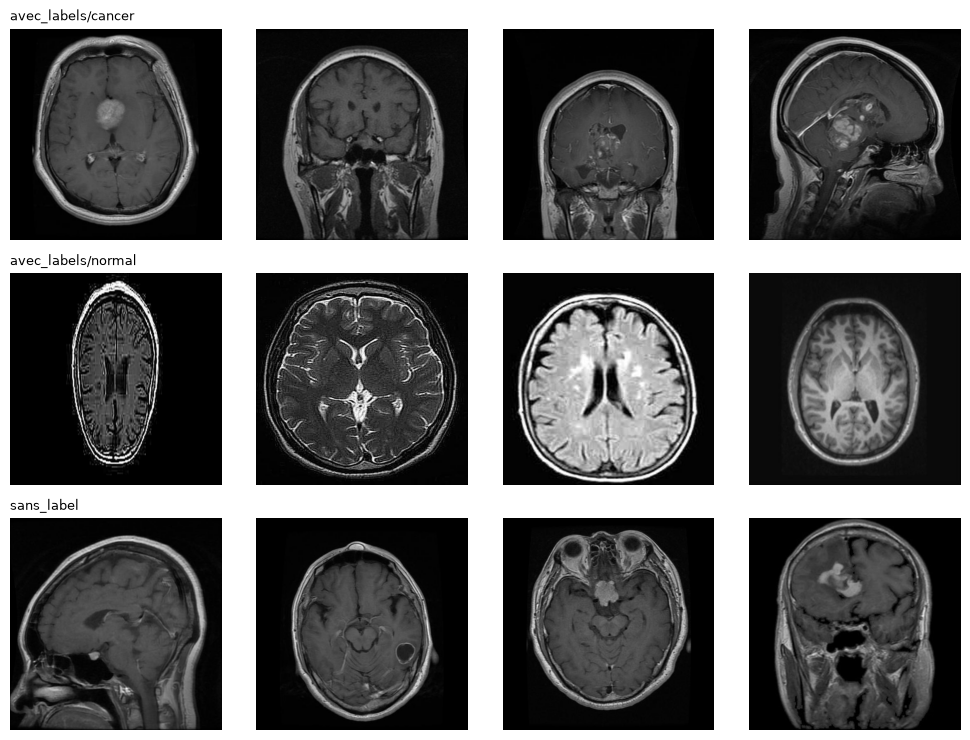

In [5]:
# -------------------------- 1.4 Exemples --------------------------
rng = np.random.RandomState(random_state)  # générateur dédié : reproductible sans toucher au seed global

groupes_affiches = [
    ("avec_labels/cancer", df_images[(df_images.groupe == "avec_labels") & (df_images.label == "cancer")]),
    ("avec_labels/normal", df_images[(df_images.groupe == "avec_labels") & (df_images.label == "normal")]),
    ("sans_label", df_images[df_images.groupe == "sans_label"]),
]

fig, axes = plt.subplots(3, 4, figsize=(10, 7.5))
for row, (titre, sous_df) in enumerate(groupes_affiches):
    echantillon = sous_df.sample(4, random_state=rng)  # 4 images au hasard dans ce sous-groupe
    for col, (_, ligne) in enumerate(echantillon.iterrows()):
        ax = axes[row, col]
        ax.imshow(Image.open(ligne["chemin"]), cmap="gray")
        ax.set_title(titre if col == 0 else "", loc="left", fontsize=9)
        ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "01_exemples_par_groupe.png", dpi=150)  # trace écrite pour le rapport/la présentation
plt.show()

✍️ *À compléter :*
- À l'œil nu, vois-tu une différence visible entre les IRM « cancer » et « normal » ? Est-ce facile ou difficile pour un non-spécialiste ?
- Les images « sans_label » ressemblent-elles globalement aux deux autres groupes, ou vois-tu déjà des cas atypiques (cadrage, contraste, bruit) ?

### 1.5 Qualité et cohérence : recherche de doublons

Deux fichiers identiques au pixel près auraient le même hash MD5. On vérifie s'il existe des doublons exacts, et surtout s'il en existe entre le jeu labellisé et le jeu sans label : ce serait un risque de fuite de données pour l'étape 3 (une image qu'on croit "nouvelle" alors qu'on en connaît déjà le vrai label).

In [6]:
# -------------------------- 1.5 Doublons exacts (hash MD5) --------------------------
import hashlib

def hash_fichier(chemin):
    return hashlib.md5(chemin.read_bytes()).hexdigest()  # hash du contenu binaire brut du fichier

df_images["md5"] = df_images["chemin"].apply(hash_fichier)

doublons = df_images[df_images.duplicated("md5", keep=False)].sort_values("md5")
groupes_doublons = doublons.groupby("md5")["groupe"].apply(lambda s: set(s))

print(f"{doublons['md5'].nunique()} groupes de fichiers identiques, {len(doublons)} fichiers concernés")
print("Groupes avec un pied dans chaque jeu (avec_labels ET sans_label) :",
      groupes_doublons.apply(lambda s: len(s) > 1).sum())

# le détail des doublons qui traversent les deux jeux : ceux qui posent un risque de fuite
fuite = doublons[doublons["md5"].isin(groupes_doublons[groupes_doublons.apply(len) > 1].index)]
fuite[["chemin", "groupe", "label", "md5"]].sort_values("md5")

90 groupes de fichiers identiques, 186 fichiers concernés
Groupes avec un pied dans chaque jeu (avec_labels ET sans_label) : 31


,chemin,groupe,label,md5
97,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,avec_labels,normal,0652cb55477c4edeea5c5dfd53944e3b
1086,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,sans_label,NaN,0652cb55477c4edeea5c5dfd53944e3b
84,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,avec_labels,normal,0816537db58c1d8092808f2c6f75e96c
369,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,sans_label,NaN,0816537db58c1d8092808f2c6f75e96c
72,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,avec_labels,normal,1868801e49e6cd18fb2e4189250921e4
...,...,...,...,...
471,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,sans_label,NaN,eaeb102cd99661f157923b9eff689053
85,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,avec_labels,normal,f95511593d8fc69f9f0a7197cb1df0dd
833,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,sans_label,NaN,f95511593d8fc69f9f0a7197cb1df0dd
51,/Users/thibaultdautheville/Documents/VSCode/Projet 7/Bra...,avec_labels,normal,fa2f6066ee4f4e22f35c46c4ddf8584b


✍️ *À compléter :*
- Combien de groupes de doublons exacts trouves-tu, et combien traversent la frontière `avec_labels` / `sans_label` ?
- En quoi est-ce un problème pour l'étape 3, où l'on doit calculer un score ARI sur les images labellisées et prédire des labels faibles pour les images sans label ?
- Que proposes-tu de faire de ces doublons avant de poursuivre (les garder, en retirer un exemplaire, lequel) ?

### Conclusion de l'étape 1

✍️ *À compléter — reprendre les observations des sections 1.1 à 1.5 pour résumer ce que l'on sait maintenant du jeu de données, et ce qui doit être traité (doublons) avant l'étape 2.*

## 2. Prétraiter les images et extraire les features (étape 2)

Objectif : préparer les images pour un réseau pré-entraîné (redimensionnement, normalisation), puis extraire un vecteur de features par image à l'aide des couches convolutionnelles **gelées** d'un CNN pré-entraîné. Ces vecteurs serviront de base à l'analyse non supervisée (étape 3).

### 2.0 Déduplication

On retire d'abord les doublons identifiés en 1.5, pour ne garder qu'un seul exemplaire par contenu réel et ne pas biaiser la suite.

In [7]:
# -------------------------- 2.0 Déduplication --------------------------
# on garde l'image labellisée en priorité quand un doublon existe entre les deux jeux,
# pour ne perdre aucune des 100 images annotées par les radiologues
df_images_dedup = (
    df_images.sort_values("groupe")  # "avec_labels" < "sans_label" dans l'ordre alphabétique : gardé en 1er
    .drop_duplicates("md5", keep="first")
    .drop(columns="md5")
    .reset_index(drop=True)
)

print(f"{len(df_images)} images avant déduplication, {len(df_images_dedup)} après")
df_images_dedup.groupby(["groupe", "label"], dropna=False).size()

1506 images avant déduplication, 1410 après


groupe       label 
avec_labels  cancer      50
             normal      49
sans_label   NaN       1311
dtype: int64

✍️ *À compléter :*
- Combien d'images ont été retirées ? Est-ce cohérent avec le nombre de doublons trouvés en 1.5 ?
- Pourquoi choisir de garder l'exemplaire « avec_labels » plutôt que « sans_label » quand les deux existent ?

### 2.1 Préparer le pipeline de prétraitement

Le modèle pré-entraîné attend des images normalisées comme celles d'ImageNet (moyenne et écart-type par canal), redimensionnées à une taille fixe.

In [8]:
# -------------------------- 2.1 Imports deep learning et transform --------------------------
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from torchvision.models import ResNet18_Weights, resnet18

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")  # GPU Apple si dispo
print("Device utilisé :", device)

# moyenne/écart-type ImageNet : le modèle a été entraîné avec cette normalisation, on la reproduit à l'identique
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),  # taille d'entrée attendue par ResNet18
    transforms.ToTensor(),  # image PIL -> tenseur, valeurs ramenées entre 0 et 1
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])


class ImagesDataset(Dataset):
    """Charge les images à partir du tableau df_images_dedup, dans l'ordre de ses lignes."""

    def __init__(self, df, transform):
        self.chemins = df["chemin"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.chemins)

    def __getitem__(self, idx):
        image = Image.open(self.chemins[idx]).convert("RGB")
        return self.transform(image)


dataset = ImagesDataset(df_images_dedup, preprocess)
loader = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=0)  # shuffle=False : on garde l'ordre du tableau
print(f"{len(dataset)} images prêtes à passer dans le modèle")

Device utilisé : mps
1410 images prêtes à passer dans le modèle


✍️ *À compléter :*
- Pourquoi utiliser précisément la moyenne et l'écart-type d'ImageNet, et pas ceux calculés sur nos propres images ?
- Pourquoi `shuffle=False` ici, alors qu'on mettrait `shuffle=True` pour entraîner un modèle ?

### 2.2 Charger le modèle pré-entraîné et geler les couches convolutionnelles

On utilise un ResNet18 pré-entraîné sur ImageNet. Les couches convolutionnelles sont gelées (pas de mise à jour des poids) : on s'en sert uniquement comme extracteur de features, sans ré-entraînement.

In [9]:
# -------------------------- 2.2 ResNet18 pré-entraîné, couches gelées --------------------------
resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)  # poids appris sur ImageNet (1,2 million d'images)

for param in resnet.parameters():
    param.requires_grad = False  # gèle tous les poids : aucun gradient ne sera calculé pour eux

resnet.fc = nn.Identity()  # on retire la dernière couche de classification : la sortie devient l'embedding brut
resnet = resnet.to(device).eval()  # mode évaluation : désactive dropout/batchnorm en mode entraînement

# vérification rapide sur une image : la dimension de sortie attendue est 512 (sortie de la couche avgpool)
exemple = next(iter(loader))[:1].to(device)
with torch.no_grad():
    sortie_exemple = resnet(exemple)
print("Dimension de l'embedding par image :", sortie_exemple.shape[1])

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/thibaultdautheville/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


  0%|          | 0.00/44.7M [00:00<?, ?B/s]

 17%|█▋        | 7.38M/44.7M [00:00<00:00, 77.0MB/s]

 37%|███▋      | 16.6M/44.7M [00:00<00:00, 88.2MB/s]

 60%|██████    | 26.9M/44.7M [00:00<00:00, 96.7MB/s]

 82%|████████▏ | 36.8M/44.7M [00:00<00:00, 99.2MB/s]

100%|██████████| 44.7M/44.7M [00:00<00:00, 96.4MB/s]

Dimension de l'embedding par image : 512


✍️ *À compléter :*
- Que signifie concrètement « geler » les couches convolutionnelles ? Que se passerait-il si on ne le faisait pas, avec seulement 100 images labellisées ?
- La dimension obtenue est-elle bien celle attendue pour un ResNet18 ? À quoi correspond-elle dans l'architecture du réseau ?

### 2.3 Extraire les embeddings de toutes les images

In [10]:
# -------------------------- 2.3 Extraction des embeddings --------------------------
embeddings = []
with torch.no_grad():  # pas de calcul de gradient : on ne fait qu'une passe avant, plus rapide et moins de mémoire
    for batch in tqdm(loader, desc="Extraction des embeddings"):
        batch = batch.to(device)
        sortie = resnet(batch)
        embeddings.append(sortie.cpu().numpy())  # retour sur CPU pour pouvoir construire un tableau numpy

embeddings = np.vstack(embeddings)
print("Forme du tableau d'embeddings :", embeddings.shape)
assert embeddings.shape[0] == len(df_images_dedup)  # une ligne d'embedding par image, dans le même ordre

Extraction des embeddings:   0%|          | 0/45 [00:00<?, ?it/s]

Extraction des embeddings:   2%|▏         | 1/45 [00:02<01:53,  2.59s/it]

Extraction des embeddings:   4%|▍         | 2/45 [00:02<00:56,  1.31s/it]

Extraction des embeddings:   7%|▋         | 3/45 [00:03<00:33,  1.24it/s]

Extraction des embeddings:   9%|▉         | 4/45 [00:03<00:24,  1.70it/s]

Extraction des embeddings:  11%|█         | 5/45 [00:03<00:18,  2.11it/s]

... (38 outputs left out)

Extraction des embeddings:  98%|█████████▊| 44/45 [00:14<00:00,  3.35it/s]

Extraction des embeddings: 100%|██████████| 45/45 [00:17<00:00,  1.16s/it]

Extraction des embeddings: 100%|██████████| 45/45 [00:17<00:00,  2.51it/s]

Forme du tableau d'embeddings : (1410, 512)


✍️ *À compléter :*
- Combien de temps/ressources cela a-t-il pris sur le Mac ? Qu'est-ce que ça laisse penser pour le budget de passage à l'échelle à 4 millions d'images évoqué par Clara ?

### 2.4 Sauvegarder le tableau de features

On associe chaque embedding à son image, son groupe et son label, puis on sauvegarde pour réutiliser ces features dans l'étape 3 sans refaire tourner le modèle.

In [11]:
# -------------------------- 2.4 Sauvegarde --------------------------
df_features = df_images_dedup[["chemin", "groupe", "label"]].copy()
df_features["chemin"] = df_features["chemin"].astype(str)
for i in range(embeddings.shape[1]):
    df_features[f"emb_{i}"] = embeddings[:, i]  # une colonne par dimension de l'embedding (512 colonnes)

PROCESSED_DATA_PATH.mkdir(parents=True, exist_ok=True)
chemin_sortie = PROCESSED_DATA_PATH / "features_resnet18.parquet"
df_features.to_parquet(chemin_sortie, index=False)

print(f"Tableau de features sauvegardé : {chemin_sortie}")
print("Dimensions :", df_features.shape)

/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_64875/1250282999.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_features[f"emb_{i}"] = embeddings[:, i]  # une colonne par dimension de l'embedding (512 colonnes)
/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_64875/1250282999.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_features[f"emb_{i}"] = embeddings[:, i]  # une colonne par dimension de l'embedding (512 colonnes)
/var/folders/76/v3gkc48n6_z8w_gst8yvldm40000gn/T/ipykernel_64875/125028299

Tableau de features sauvegardé : /Users/thibaultdautheville/Documents/VSCode/Projet 7/BrainScanAI-semi-supervise/data/processed/features_resnet18.parquet
Dimensions : (1410, 515)


✍️ *À compléter :*
- Pourquoi sauvegarder les features dans un fichier plutôt que de relancer l'extraction à chaque fois que tu rouvres le notebook ?

### Conclusion de l'étape 2

✍️ *À compléter — résumer la démarche de prétraitement et d'extraction, et ce qui est maintenant disponible pour l'étape 3 (analyse non supervisée).*